# A series with no alignment

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/02_no_alignment.ipynb)

The overlap kernel of the first notebook compares two molecules point by point, so it needs them
in one frame: an alignment. Many series have no alignment and no obvious way to make one, for
example a table of binding constants of unrelated guests to one host. This notebook builds a
model on such a table with the rotation-invariant autocorrelation kernel, which compares the
distance distributions of the fields inside each molecule and needs no frame at all.

The manual explains the kernel in *Working without an alignment*. The data are the association
constants of 292 guests with gamma-cyclodextrin (`examples/cyclodextrin/gamma_cyclodextrin.csv`),
a SMILES table.

Running time: about a minute, most of it building a 3D structure for every SMILES.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## From SMILES to fields

`load_dataset` reads a SMILES table and gives every molecule its own 3D structure. The
structures are in no common frame, which is the point: the kernel below does not care.

In [2]:
from cmfqsar import load_dataset, FieldSet
from cmfqsar.fields import AtomTable, build_fields

ds = load_dataset("examples/cyclodextrin/gamma_cyclodextrin.csv", activity_prop="activity")
fs = FieldSet.create(alpha=1.0)
mf = [build_fields(m, fs, n) for m, n in zip(ds.mols, ds.names)]
train = AtomTable.from_molecules(mf)
print(len(ds), "guests, log K from %.2f to %.2f" % (ds.activity.min(), ds.activity.max()))

292 guests, log K from 0.30 to 4.81


## The rotation-invariant kernel

`kernel_source="autocorrelation"` switches the model from overlap integrals to the
autocorrelation of the fields: for every pair of field types, the distribution of the
interatomic distances weighted by the two fields. `ac_sigma` is the width along the distance axis
and `ac_d_max` the longest distance resolved. Only *lambda* needs to be chosen here; the Gaussian
width *alpha* of the fields is kept at one angstrom.

In [3]:
from cmfqsar import CMFModel
from cmfqsar.model import grid_search

model = CMFModel(fieldset=fs, method="krr", normalize=True,
                 kernel_source="autocorrelation", ac_sigma=0.75, ac_d_max=12.0)
grid_search(train, ds.activity, model, alphas=[1.0], lams=[1e-3, 1e-2, 0.1, 1.0])
model.fit(train, ds.activity, cv_folds=10)
print(model.stats.summary())

Training set: n = 292
  r2 (fit)        = 0.715    RMSE (fit)  = 0.478
  q2 (10-fold CV)  = 0.485    RMSEcv      = 0.642


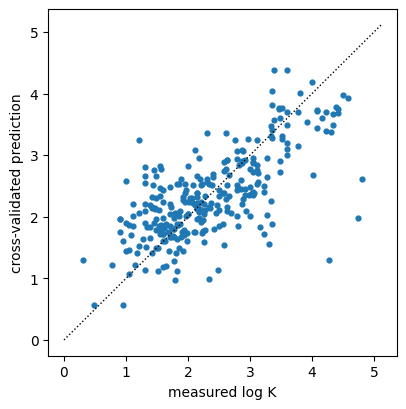

In [4]:
import numpy as np
import matplotlib.pyplot as plt

y, y_cv = ds.activity, model.stats.extra["y_cv"]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(y, y_cv, s=12)
lo, hi = y.min() - 0.3, y.max() + 0.3
ax.plot([lo, hi], [lo, hi], "k:", lw=1)
ax.set_xlabel("measured log K"); ax.set_ylabel("cross-validated prediction"); plt.show()

## Which atoms the prediction came from

The autocorrelation channels are sums over atom pairs, so a prediction can still be split over
the atoms of a molecule. Below, the atoms of one guest are coloured by their share: blue raises
the predicted constant, red lowers it.

In [5]:
def view_contributions(m, contrib, size=(560, 400)):
    """The molecule with its atoms coloured by contribution (blue positive, red negative)."""
    try:
        import py3Dmol
    except ImportError:
        print("py3Dmol is not installed (pip install py3Dmol); the 3D view is skipped")
        return None
    scale = np.abs(contrib).max() or 1.0
    v = py3Dmol.view(width=size[0], height=size[1])
    v.addModel(m.molblock, "mol")
    v.setStyle({"stick": {"radius": 0.12, "color": "lightgray"}})
    for i, c in enumerate(contrib):
        t = float(abs(c) / scale)
        color = "#%02x%02x%02x" % ((int(255 * (1 - t)), int(255 * (1 - t)), 255) if c > 0
                                   else (255, int(255 * (1 - t)), int(255 * (1 - t))))
        v.addStyle({"serial": i + 1}, {"sphere": {"scale": 0.28, "color": color}})
    v.zoomTo()
    return v.show()

best = int(np.argmax(y))
m = mf[best]
contrib = model.atom_contributions(m)
print(ds.names[best], ": measured %.2f, predicted %.2f" % (y[best], model.predict(AtomTable.from_molecules([m]))[0]))
view_contributions(m, contrib)

benzo[a]pyrene : measured 4.81, predicted 2.75


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Predicting new guests

A new molecule needs the same treatment as the training set: a 3D structure, then fields. Any
structure will do, since the kernel ignores the frame.

In [6]:
from rdkit import Chem
from cmfqsar.align import embed_3d

new_smiles = {"adamantane": "C1C2CC3CC1CC(C2)C3",
              "1-naphthol": "Oc1cccc2ccccc12",
              "sodium benzoate (benzoate anion)": "O=C([O-])c1ccccc1"}
new = []
for name, smi in new_smiles.items():
    mol = embed_3d(Chem.AddHs(Chem.MolFromSmiles(smi)), seed=1)
    new.append(build_fields(mol, fs, name))
for name, p in zip(new_smiles, model.predict(AtomTable.from_molecules(new))):
    print("%-35s predicted log K = %.2f" % (name, p))

adamantane                          predicted log K = 2.05
1-naphthol                          predicted log K = 1.81
sodium benzoate (benzoate anion)    predicted log K = 3.37


## The same model from the command line

```
cmf build examples/cyclodextrin/gamma_cyclodextrin.csv --kernel autocorrelation --save gamma.cmf
cmf predict gamma.cmf new_guests.smi
```

The manual's chapter *Working without an alignment* compares this kernel with the two other
frame-free routes, the pose-free count kernel and topomer fields, on the benchmark sets. The next
notebook, *Trusting a prediction*, asks how far a model's numbers can be believed.